1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



2. Load the dataset

In [5]:
df = pd.read_csv('Retail_Sales_Data.csv')

print("Dataset Loaded Successfully!")
print(df.head())

Dataset Loaded Successfully!
   Unnamed: 0                              Sales_ID Product_Category  \
0           0  efc35a5f-e48c-4803-9f6d-ef32a60e1367           Movies   
1           1  92a86e42-de42-4e0d-89f3-bbb0b7f354bd     Pet Supplies   
2           2  1fbbdc48-f405-48f3-8274-750581552d26          Outdoor   
3           3  1f329e7a-13f0-4518-9eeb-84815301d64c      Electronics   
4           4  6ef559dc-3e68-4009-9845-4bab54d897c6            Books   

   Sales_Amount  Discount      Sales_Region Date_of_Sale  Customer_Age  \
0        341.05     45.98    East Dianeport   2024-07-12          69.0   
1        594.71     29.59       North Linda   2024-05-07          32.0   
2        351.90     49.78  Lake Josephmouth   2024-05-11          28.0   
3           NaN       NaN  North Martinside   2024-09-02           NaN   
4        795.75     27.21      Michealshire   2024-05-02          21.0   

  Customer_Gender Sales_Representative  
0            Male      Bruce Rodriguez  
1          

3. Explore the dataset

In [6]:
print("First Five Rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nDataset Shape:")
print(df.shape)

print("\nStatistical Summary:")
print(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())

First Five Rows:
   Unnamed: 0                              Sales_ID Product_Category  \
0           0  efc35a5f-e48c-4803-9f6d-ef32a60e1367           Movies   
1           1  92a86e42-de42-4e0d-89f3-bbb0b7f354bd     Pet Supplies   
2           2  1fbbdc48-f405-48f3-8274-750581552d26          Outdoor   
3           3  1f329e7a-13f0-4518-9eeb-84815301d64c      Electronics   
4           4  6ef559dc-3e68-4009-9845-4bab54d897c6            Books   

   Sales_Amount  Discount      Sales_Region Date_of_Sale  Customer_Age  \
0        341.05     45.98    East Dianeport   2024-07-12          69.0   
1        594.71     29.59       North Linda   2024-05-07          32.0   
2        351.90     49.78  Lake Josephmouth   2024-05-11          28.0   
3           NaN       NaN  North Martinside   2024-09-02           NaN   
4        795.75     27.21      Michealshire   2024-05-02          21.0   

  Customer_Gender Sales_Representative  
0            Male      Bruce Rodriguez  
1           Other      

4. Data Cleaning

In [13]:
# Remove unnecessary index column
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows where Sales_Amount is missing
df = df.dropna(subset=['Sales_Amount'])

# Fill missing numerical values
df['Discount'] = df['Discount'].fillna(df['Discount'].median())

df['Customer_Age'] = df['Customer_Age'].fillna(
    df['Customer_Age'].median()
)

# Fill missing gender
df['Customer_Gender'] = df['Customer_Gender'].fillna(
    df['Customer_Gender'].mode()[0]
)

print("\nData Cleaning Completed!")
print(df.isnull().sum())

Missing Values:
Sales_ID                0
Product_Category        0
Sales_Amount            0
Discount                0
Sales_Region            0
Date_of_Sale            0
Customer_Age            0
Customer_Gender         0
Sales_Representative    0
Sales                   0
dtype: int64

Data Cleaning Completed!
Sales_ID                0
Product_Category        0
Sales_Amount            0
Discount                0
Sales_Region            0
Date_of_Sale            0
Customer_Age            0
Customer_Gender         0
Sales_Representative    0
Sales                   0
dtype: int64


5. Convert date into datetime format

In [14]:
df['Date_of_Sale'] = pd.to_datetime(df['Date_of_Sale'])

# Extract year and month
df['Year'] = df['Date_of_Sale'].dt.year

df['Month'] = df['Date_of_Sale'].dt.month

print(df.head())

                               Sales_ID Product_Category  Sales_Amount  \
0  efc35a5f-e48c-4803-9f6d-ef32a60e1367           Movies        341.05   
1  92a86e42-de42-4e0d-89f3-bbb0b7f354bd     Pet Supplies        594.71   
2  1fbbdc48-f405-48f3-8274-750581552d26          Outdoor        351.90   
4  6ef559dc-3e68-4009-9845-4bab54d897c6            Books        795.75   
5  280065cd-ad2b-4c80-9fce-929da484ee06            Books        526.17   

   Discount      Sales_Region Date_of_Sale  Customer_Age Customer_Gender  \
0     45.98    East Dianeport   2024-07-12          69.0            Male   
1     29.59       North Linda   2024-05-07          32.0           Other   
2     49.78  Lake Josephmouth   2024-05-11          28.0           Other   
4     27.21      Michealshire   2024-05-02          21.0           Other   
5     28.54         Joelmouth   2024-01-02          61.0          Female   

  Sales_Representative   Sales  Year  Month  
0      Bruce Rodriguez  341.05  2024      7  
1     

6. Group sales by region

In [15]:
region_sales = df.groupby('Sales_Region')['Sales_Amount'].sum()

print("Total Sales by Region:")
print(region_sales.sort_values(ascending=False).head(10))

Total Sales by Region:
Sales_Region
South Michael       45991.44
Lake Michael        43439.88
New Michael         41517.00
North John          40308.55
West Michael        38881.67
North Michael       38533.22
Port Michael        38270.12
East Michael        37818.75
Michaelmouth        35502.70
West Christopher    34782.92
Name: Sales_Amount, dtype: float64


7. Group sales by product category

In [16]:
category_sales = df.groupby('Product_Category')['Sales_Amount'].sum()

print("Sales by Product Category:")
print(category_sales.sort_values(ascending=False))

Sales by Product Category:
Product_Category
Movies             2127649.79
Toys               2107808.73
Books              2104440.86
Jewelry            2098907.32
Appliances         2096142.06
Personal Care      2091050.94
Groceries          2090515.92
Health             2087823.44
Music              2086191.80
Beauty             2081590.41
Sports             2078401.50
Furniture          2076003.13
Office Supplies    2064491.58
Clothing           2061267.99
Pet Supplies       2051885.55
Baby Products      2046518.86
Garden             2045201.33
Outdoor            2036937.30
DIY                2034444.29
Tools              2022642.75
Home & Kitchen     2022613.49
Electronics        2011872.37
Software           1997551.15
Automotive         1993419.97
Name: Sales_Amount, dtype: float64


8. Group sales by region and product category

In [17]:
region_category = df.groupby(
    ['Sales_Region', 'Product_Category']
)['Sales_Amount'].sum()

print("Sales by Region and Category:")
print(region_category.head(10))

Sales by Region and Category:
Sales_Region  Product_Category
Aaronberg     Automotive          890.70
              Books               829.89
              DIY                 121.72
              Electronics         554.26
              Music               478.55
              Personal Care       273.36
              Tools               721.47
              Toys                664.31
Aaronborough  Books               208.11
              DIY                 671.42
Name: Sales_Amount, dtype: float64


9. Calculate total and average sales

In [19]:
total_sales = df['Sales_Amount'].sum()

average_sales = df['Sales_Amount'].mean()

print("Total Sales:", total_sales)

print("Average Sales:", average_sales)

Total Sales: 49515372.53
Average Sales: 550.1708058888889


10. Find top-performing region

In [20]:
top_region = region_sales.idxmax()

highest_sales = region_sales.max()

print("Top Performing Region:", top_region)

print("Highest Sales:", highest_sales)

Top Performing Region: South Michael
Highest Sales: 45991.44


11. Data Visualization


A. Bar Chart – Sales by Region

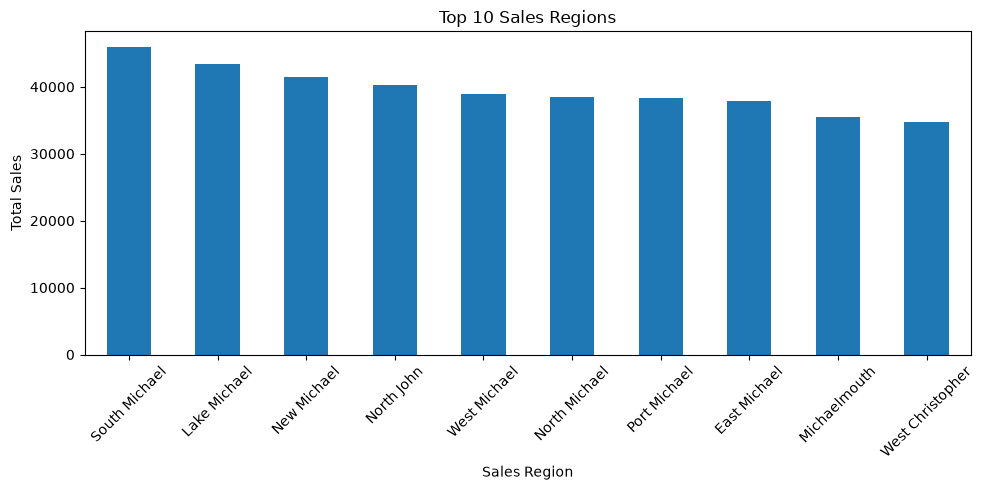

In [21]:
top_regions = region_sales.sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(10, 5))

top_regions.plot(kind='bar')

plt.title("Top 10 Sales Regions")
plt.xlabel("Sales Region")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

B. Pie Chart – Sales Distribution by Region

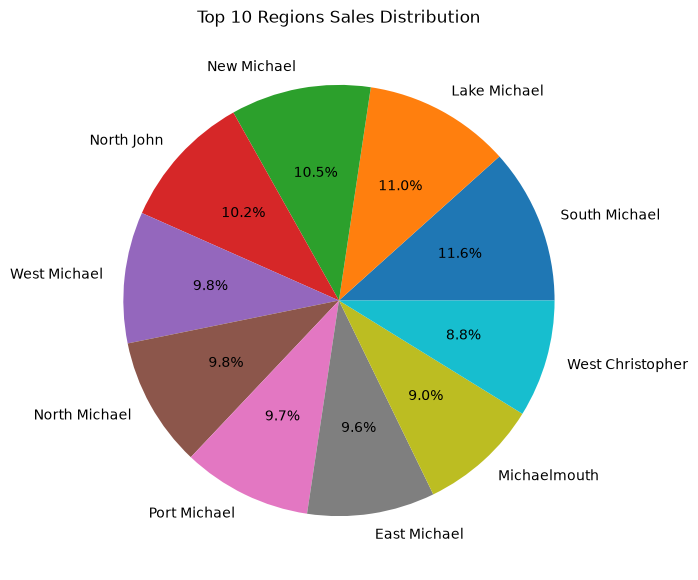

In [22]:
plt.figure(figsize=(7, 7))

top_regions.plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title("Top 10 Regions Sales Distribution")
plt.ylabel("")

plt.show()

C. Bar Chart – Sales by Product Category

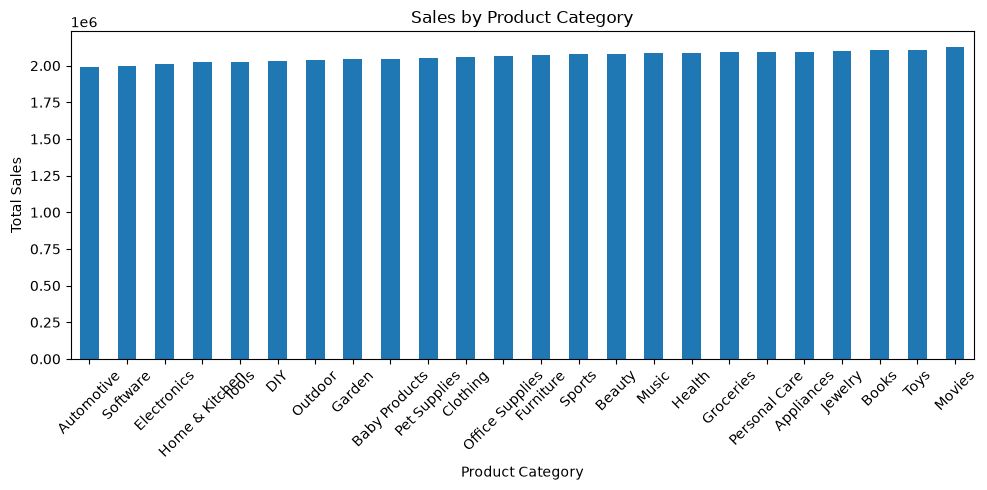

In [23]:
plt.figure(figsize=(10, 5))

category_sales.sort_values().plot(kind='bar')

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

D. Stacked Bar Chart – Region vs Product Category

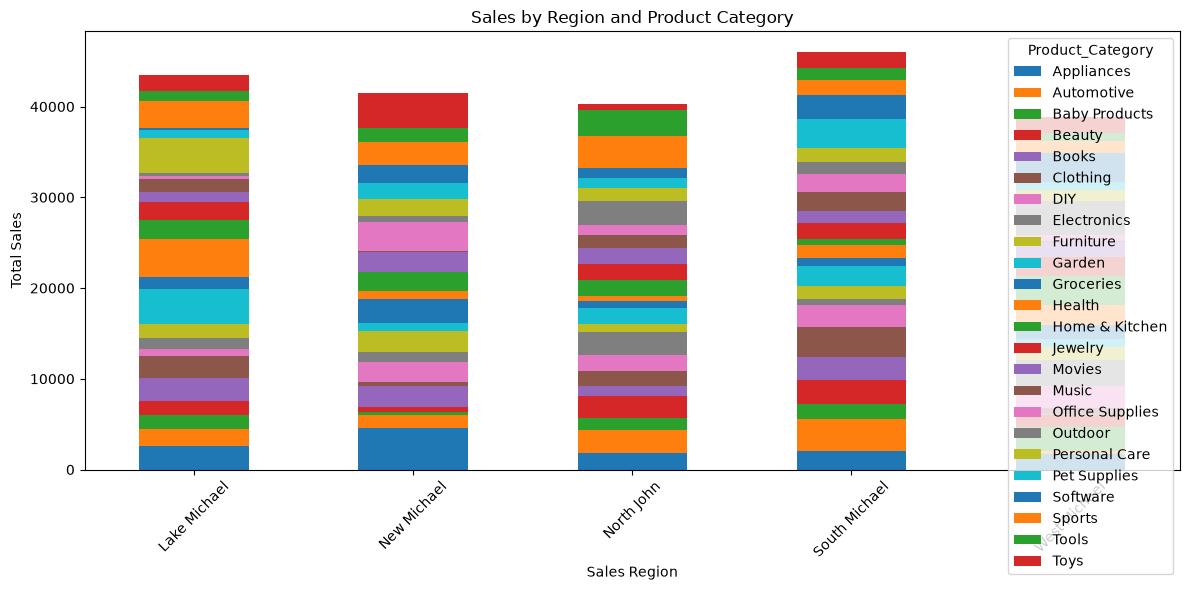

In [24]:
top_5_regions = region_sales.sort_values(
    ascending=False
).head(5).index

filtered_df = df[df['Sales_Region'].isin(top_5_regions)]

pivot_data = filtered_df.pivot_table(
    values='Sales_Amount',
    index='Sales_Region',
    columns='Product_Category',
    aggfunc='sum',
    fill_value=0
)

pivot_data.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("Sales by Region and Product Category")
plt.xlabel("Sales Region")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

E. Line Chart – Monthly Sales Trend

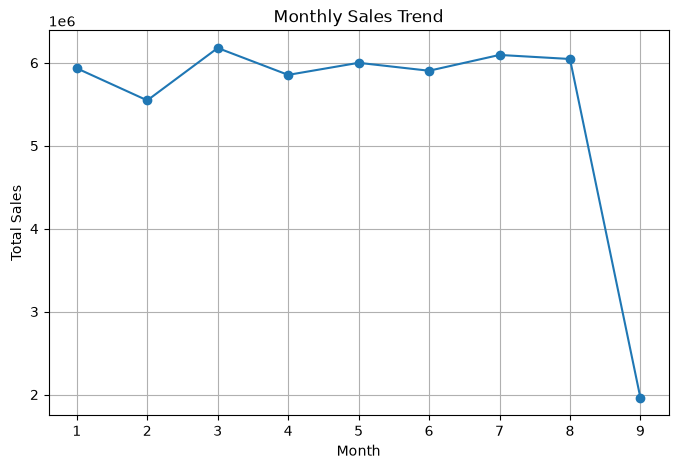

In [26]:
monthly_sales = df.groupby('Month')['Sales_Amount'].sum()

plt.figure(figsize=(8, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker='o')

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.grid()
plt.show()